# Barnstable and Long-Run Risk — Group Case

**FINM 36700 Portfolio and Risk Management**

Case link: [Barnstable and Long-Run Risk](https://markhendricks.github.io/finm-portfolio/case_studies/Barnstable%20and%20Long-Run%20Risk.html)

# 1. Reading: Barnstable

## 1. Barnstable's Philosophy
> What has Barnstable's investment strategy been in the past? Explain the logic behind their view that stocks are safer in the long run. What assumptions underlie Barnstable's belief in the long-run safety of stocks?

Barnstable has held stocks directly in a conventional, unlevered portfolio. Its view that stocks are safer in the long run comes from time diversification: if annual log returns are i.i.d. with mean $\mu$ and volatility $\sigma$, the $h$-year average return has volatility $\sigma/\sqrt{h}$, so the chance of falling short of the risk-free rate shrinks toward zero as $h$ grows (about 2% over 30 years using the 1965–1999 data in Section 2). This relies on returns being i.i.d. and normal, on the mean being known rather than estimated, and on the probability of a shortfall, rather than its size, being the right measure of risk.

## 2. Two Proposals
> Describe the two proposals Barnstable is considering for how to take advantage of their view regarding the long-run safety of stocks.

Both proposals bet that stocks will earn more than 6% per year over 30 years, a hurdle of $K = e^{0.06 \times 30} \approx 6.05$ per \$1 invested. In the **trust**, a trust holds the S&P 500 for 30 years; preferred shares receive its value up to the hurdle, and Barnstable buys the common shares, which receive everything above it. In the **put proposal**, Barnstable sells 30-year puts on the S&P 500 with a strike at the hurdle and collects the premium today.

## 3. The Trust
> How is the trust different from simply shorting the risk-free rate to take a levered position in stocks?

A levered position pays $R^m_{t,t+30} - K$, so Barnstable owes the shortfall if stocks fall short. The common share pays $\max(R^m_{t,t+30} - K,\ 0)$: Barnstable's loss is limited to what it paid, and the preferred shareholders absorb the rest. The common share is therefore a levered position plus a put. That makes it more expensive up front, but it also means Barnstable cannot be forced out by margin calls before maturity.

## 4. Payoff Differences
> Do these proposals take the same bet on long-run stock performance? In what outcomes will they have different returns?

They take the same directional bet but pay off differently. If stocks beat the hurdle, the common share keeps rising with the market, while the put seller only keeps the premium. If stocks fall short, the common share is worth zero, while the put seller pays the full shortfall, $K - R^m_{t,t+30}$, which can be up to about \$6 per \$1 of stock. The common share is a call and selling puts is a short put; together they make up a levered stock position.

## 5. Risk Differences
> Do the two proposals differ in their risk?

Yes. The trust's worst case is losing the price of the common shares. The put seller collects a premium but faces losses many times larger, and those losses come in the bad states when the endowment's other stock holdings are also down. The low shortfall probability behind both proposals is also fragile: from the Full Sample Analysis in Section 2, if the true mean is one or two standard errors lower, the 30-year probability of underperforming T-bills rises from about 1.7% to about 8% or 24%.

## 6. Recommendation
> Do you recommend a direct investment in the S&P, the trust or the puts?

We recommend a direct investment in the S&P 500 and recommend against the puts. Neither proposal is a free lunch: if the options are fairly priced, both are just repackaged levered stock exposure, and Barnstable's case for them ignores the size of the losses and the uncertainty in the mean. The puts carry the worst tail risk. The trust caps the loss but is still a levered bet with added cost and complexity. If Barnstable wants more stock exposure, it can raise its S&P 500 allocation directly.

# 2. Estimating Underperformance

* **Data:** `data/barnstable_analysis_data.xlsx`, monthly CRSP S&P 500 total returns (`SPX`) and 1-month T-bill rates (`TB1M`), January 1926 – December 2025 (1,200 months).
* **Notation:** $r$ = level return, $R = 1 + r$ = gross return, $\texttt{r} = \ln(1 + r)$ = log return. A tilde denotes excess over the risk-free rate.
* **Format:** means are annualized × 12, volatilities × $\sqrt{12}$.

## 1. Summary Statistics

In [1]:
# 1. Summary Statistics
import pandas as pd, numpy as np

df = pd.read_excel("data/barnstable_analysis_data.xlsx", sheet_name="data",
                   parse_dates=["date"]).set_index("date")

# level returns (stock, T-bill, excess) and log returns
lev = pd.DataFrame({"SPX": df.SPX, "TB1M": df.TB1M})
lev["EXCESS"] = lev.SPX - lev.TB1M
log = np.log1p(df[["SPX", "TB1M"]])
log["EXCESS"] = log.SPX - log.TB1M

P = {"1965-1999": ("1965", "1999"), "2000-2025": ("2000", "2025"), "1926-2025": ("1926", "2025")}

rows = {}
for s in lev:
    for k, d in (("levels", lev), ("logs", log)):
        rows[(s, k)] = {(p, m): v for p, (a, b) in P.items() for m, v in
                        zip(("mean", "vol"),
                            (12 * d.loc[a:b, s].mean(),          # annualized mean
                             np.sqrt(12) * d.loc[a:b, s].std()))} # annualized vol
table = pd.DataFrame(rows).T
print(table.round(4).to_string())

              1965-1999         2000-2025         1926-2025        
                   mean     vol      mean     vol      mean     vol
SPX    levels    0.1294  0.1494    0.0908  0.1514    0.1161  0.1860
       logs      0.1176  0.1496    0.0790  0.1523    0.0985  0.1853
TB1M   levels    0.0615  0.0072    0.0183  0.0056    0.0318  0.0084
       logs      0.0613  0.0071    0.0182  0.0056    0.0318  0.0084
EXCESS levels    0.0679  0.1501    0.0726  0.1516    0.0843  0.1863
       logs      0.0563  0.1503    0.0608  0.1525    0.0667  0.1855


-Full sample volatility is actually higher than both sub samples. This trend is consistent across SPX and TB1M, and the Excess as well. Mean returns for SPX were the best in 1965-1999, same for TBIM. What this indicates is that the past 25 years may actually be a low performer for stocks as a proxy of American economic growth. An interesting next step would be to see how AI impacts these predictions as we lose as data for 2026 in this anaylsis but that's a thing for next year's students to think about. 

Level stats for SPX show compounding while with TBIM they are scarily close to the level results. This is because mean log returns are lower than mean level returns by roughly half the variance ($\tfrac{1}{2}\sigma^2$): stock volatility is about 15%, so the gap is about 1.1%, while T-bill volatility is under 1%, so the gap is negligible.

## 2. Probability of Underperformance

> Calculate the probability that the cumulative market return will fall short of the cumulative risk-free return, $\Pr\left[R^m_{t,t+h} < R^f_{t,t+h}\right]$.

**Converting to a statement about mean log returns.** The log function is increasing, and cumulative log returns are sums of one-period log returns:

$$
R^m_{t,t+h} < R^f_{t,t+h}
\;\iff\; \sum_{i=1}^{h} \texttt{r}^m_{t+i} < \sum_{i=1}^{h} \texttt{r}^f_{t+i}
\;\iff\; \bar{\tilde{\texttt{r}}}^m_{t,t+h} < 0,
$$

where $\tilde{\texttt{r}}^m = \texttt{r}^m - \texttt{r}^f$ is the log excess return and $\bar{\tilde{\texttt{r}}}^m_{t,t+h}$ is its $h$-year average.

If annual log excess returns are i.i.d. normal with mean $\tilde{\mu}$ and volatility $\tilde{\sigma}$, then the $h$-year average is normal with mean $\tilde{\mu}$ and volatility $\tilde{\sigma}/\sqrt{h}$. Therefore

$$
p(h) = \Pr\left[\bar{\tilde{\texttt{r}}}^m_{t,t+h} < 0\right]
= \Phi\!\left(\frac{0 - \tilde{\mu}}{\tilde{\sigma}/\sqrt{h}}\right)
= \Phi\!\left(-\sqrt{h}\;\text{SR}\right),
\qquad \text{SR} = \frac{\tilde{\mu}}{\tilde{\sigma}},
$$

with $\tilde{\mu}$ and $\tilde{\sigma}$ annualized and $h$ measured in years.

In [2]:
from scipy.stats import norm
import matplotlib.pyplot as plt

def log_excess_moments(start, end):
    # Annualized mean, vol, and Sharpe ratio of monthly log excess returns over [start, end]
    x = log.loc[start:end, 'EXCESS']
    mu, sig = 12 * x.mean(), np.sqrt(12) * x.std()
    return pd.Series({'Mean': mu, 'Vol': sig, 'Sharpe': mu / sig, 'Months': len(x)})

def prob_underperform(h, sharpe):
    # p(h) = Phi(-sqrt(h) * SR), h in years
    return norm.cdf(-np.sqrt(h) * sharpe)

### 2.1
> Calculate the probability using the subsample 1965–1999.

In [3]:
mom_99 = log_excess_moments('1965', '1999')
SR_99  = mom_99['Sharpe']
display(mom_99.to_frame('1965-1999 (log excess)').T.style.format(
    {'Mean': '{:.2%}', 'Vol': '{:.2%}', 'Sharpe': '{:.4f}', 'Months': '{:.0f}'}))

print(f'p(h) = Phi(-sqrt(h) x {SR_99:.4f})')
pd.Series({h: prob_underperform(h, SR_99) for h in [1, 5, 10, 15, 20, 30]},
          name='Pr[stocks < T-bills]').rename_axis('h (years)').to_frame().style.format('{:.2%}')

,Mean,Vol,Sharpe,Months
1965-1999 (log excess),5.63%,15.03%,0.3746,420


p(h) = Phi(-sqrt(h) x 0.3746)


,Pr[stocks < T-bills]
h (years),
1,35.40%
5,20.11%
10,11.81%
15,7.34%
20,4.69%
30,2.01%


Using Barnstable's 1965–1999 estimates, the annualized log excess return has mean ≈ 5.63% and volatility ≈ 15.03%, giving a Sharpe ratio of ≈ 0.375. Over a single year, stocks underperform T-bills with probability ≈ 35%. The probability falls quickly as the horizon lengthens.

### 2.2
> Report the precise probability for $h = 15$ and $h = 30$ years.

In [4]:
p_99 = pd.Series({h: prob_underperform(h, SR_99) for h in [15, 30]}, name='Pr[stocks < T-bills], 1965-1999')
print(p_99.rename_axis('h (years)').to_string(float_format=lambda v: f'{v:.6f}  ({v:.4%})'))

h (years)
15   0.073402  (7.3402%)
30   0.020089  (2.0089%)


* **$h = 15$:** $p = \Phi(-\sqrt{15} \times 0.3746) \approx$ **7.34%**
* **$h = 30$:** $p = \Phi(-\sqrt{30} \times 0.3746) \approx$ **2.01%**

On these estimates, the chance that stocks fail to beat T-bills over 30 years is only about 1 in 50. This is the core of Barnstable's argument that stocks are "safe" in the long run.

### 2.3
> Plot the probability as a function of the investment horizon, $h$, for $0 < h \le 30$ years.

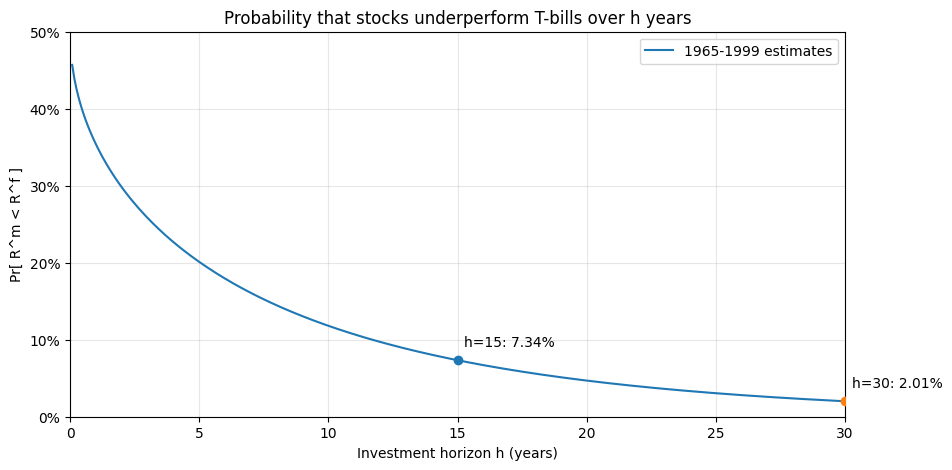

In [5]:
h_grid = np.arange(1, 30 * 12 + 1) / 12          # monthly steps from 1/12 to 30 years

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(h_grid, prob_underperform(h_grid, SR_99), label='1965-1999 estimates')
for h in [15, 30]:
    p = prob_underperform(h, SR_99)
    ax.scatter(h, p, zorder=3)
    ax.annotate(f'h={h}: {p:.2%}', (h, p), textcoords='offset points', xytext=(5, 10))
ax.set_xlim(0, 30)
ax.set_ylim(0, 0.5)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_xlabel('Investment horizon h (years)')
ax.set_ylabel('Pr[ R^m < R^f ]')
ax.set_title('Probability that stocks underperform T-bills over h years')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

**Takeaways (2.3)**

* The probability starts near 50% for very short horizons, ≈ 35% at one year, and falls steadily: about 7% at 15 years and 2% at 30 years. It falls because the mean of the $h$-year average log return stays at $\tilde{\mu}$ while its volatility shrinks like $1/\sqrt{h}$. Equivalently, the Sharpe ratio of the cumulative return grows like $\sqrt{h}$.
* **A low probability of underperformance is not the same as low risk.** The volatility of the *cumulative* log return grows like $\sigma\sqrt{h}$, so the dollar size of a bad outcome grows with the horizon. Stocks lose to T-bills less often over 30 years, but when they do, the shortfall can be very large. This is why the trust and the put proposal in Section 1 are so risky.
* The result depends on the assumptions behind the formula: returns that are i.i.d. normal and, most importantly, a **known** mean. In reality $\tilde{\mu}$ is estimated with substantial error (Section 3 shows how much this matters).

## 3. Full Sample Analysis
> Use the sample 1965–2025 to reconsider the 30-year probability. As of the end of 2025, calculate the probability of the stock return underperforming the risk-free rate over the next 30 years. That is, $R^m_{t,t+h}$ underperforming $R^f_{t,t+h}$ for $0 < h \le 30$.

,Mean,Vol,Sharpe,Months
1965-1999,5.63%,15.03%,0.3746,420
1965-2025,5.82%,15.11%,0.3852,732


,1965-1999,1965-2025
h (years),,
1,35.40%,35.01%
15,7.34%,6.79%
30,2.01%,1.74%


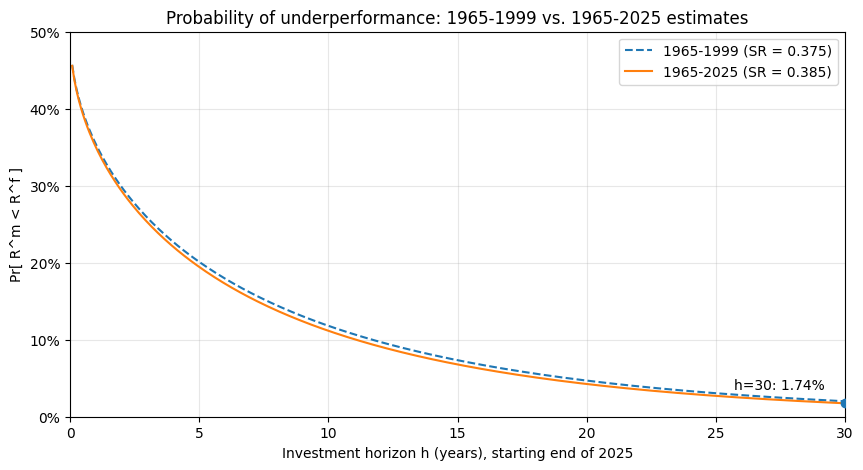

In [6]:
mom_25 = log_excess_moments('1965', '2025')
SR_25  = mom_25['Sharpe']

display(pd.DataFrame({'1965-1999': mom_99, '1965-2025': mom_25}).T.style.format(
    {'Mean': '{:.2%}', 'Vol': '{:.2%}', 'Sharpe': '{:.4f}', 'Months': '{:.0f}'}))

display(pd.DataFrame({
    '1965-1999': {h: prob_underperform(h, SR_99) for h in [1, 15, 30]},
    '1965-2025': {h: prob_underperform(h, SR_25) for h in [1, 15, 30]},
}).rename_axis('h (years)').style.format('{:.2%}'))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(h_grid, prob_underperform(h_grid, SR_99), label=f'1965-1999 (SR = {SR_99:.3f})', ls='--')
ax.plot(h_grid, prob_underperform(h_grid, SR_25), label=f'1965-2025 (SR = {SR_25:.3f})')
p30 = prob_underperform(30, SR_25)
ax.scatter(30, p30, zorder=3)
ax.annotate(f'h=30: {p30:.2%}', (30, p30), textcoords='offset points', xytext=(-80, 10))
ax.set_xlim(0, 30)
ax.set_ylim(0, 0.5)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_xlabel('Investment horizon h (years), starting end of 2025')
ax.set_ylabel('Pr[ R^m < R^f ]')
ax.set_title('Probability of underperformance: 1965-1999 vs. 1965-2025 estimates')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [7]:
# Estimation error in the mean: how sensitive is the 30-year probability?
T_years = mom_25['Months'] / 12
se_mu   = mom_25['Vol'] / np.sqrt(T_years)                  # standard error of the annualized mean

sens = pd.DataFrame({
    'Assumed mean': [mom_25['Mean'] + k * se_mu for k in [1, 0, -1, -2]],
}, index=['+1 SE', 'Point estimate', '-1 SE', '-2 SE'])
sens['Sharpe']   = sens['Assumed mean'] / mom_25['Vol']
sens['p(h=30)']  = prob_underperform(30, sens['Sharpe'])

print(f'Standard error of the annualized mean (1965-2025): {se_mu:.2%}')
sens.style.format({'Assumed mean': '{:.2%}', 'Sharpe': '{:.3f}', 'p(h=30)': '{:.2%}'})

Standard error of the annualized mean (1965-2025): 1.94%


,Assumed mean,Sharpe,p(h=30)
+1 SE,7.76%,0.513,0.25%
Point estimate,5.82%,0.385,1.74%
-1 SE,3.89%,0.257,7.95%
-2 SE,1.95%,0.129,23.98%


**Takeaways (3)**

* **Updated 30-year probability: ≈ 1.74%**, slightly *lower* than Barnstable's 2.01%. Adding 2000–2025 raised the estimated mean log excess return (5.63% → 5.82%) and barely changed volatility (15.03% → 15.11%), so the Sharpe ratio rose from 0.375 to 0.385.
* This may seem surprising, given that 2000–2025 included two major crashes (2000–02 and 2008) and stock returns were lower (≈ 7.9% vs. 11.8% mean log return, see Summary Statistics). But T-bill rates fell even more (≈ 1.8% vs. 6.1%), so the **excess** return actually came in a bit higher (≈ 6.1% vs. 5.6%). What matters for underperformance relative to T-bills is the excess return.
* Under the i.i.d. model the forecast does not depend on current conditions ("as of the end of 2025"). It only uses the sample moments, so the answer is the same $p(h)$ curve evaluated with the 1965–2025 Sharpe ratio.
* **The real risk is estimation error in the mean.** With 61 years of data, the standard error of the annualized mean is ≈ 1.9%, a third of the estimate itself. If the true mean is just one standard error lower than the point estimate, the 30-year probability rises from ≈ 1.7% to ≈ 8%. At two standard errors lower it rises to ≈ 24%. The tiny probabilities above treat $\tilde{\mu}$ as known. Uncertainty about the mean does **not** diversify away over time, which undercuts the claim that stocks are safe in the long run.

## 4. In-Sample Estimate of Out-of-Sample Likelihood
> Let's consider how things turned out relative to Barnstable's 1999 expectations. What was the probability (based on the 1999 estimate of $\mu$) that the $h$-year market return, $R^m_{t,t+h}$, would be smaller than that realized in 2000–2025?

**Setup.** Using the 1965–1999 estimates as the "1999 beliefs," the $h$-year average log market return is normal with mean $\bar{\texttt{r}}_{\text{in}}$ and volatility $\sigma_{\text{in}}/\sqrt{h}$. With $h = 26$ years (2000–2025), the probability of an average at or below the realized $\bar{\texttt{r}}_{\text{out}}$ is

$$
p = \Phi\!\left(\sqrt{h}\;\frac{\bar{\texttt{r}}_{\text{out}} - \bar{\texttt{r}}_{\text{in}}}{\sigma_{\text{in}}}\right).
$$

Here $\texttt{r}$ is the log return on the S&P 500 (the market return).

In [8]:
# 4. In-sample estimate of out-of-sample likelihood
def oos_prob(series, h=26):
    # p = Phi( sqrt(h) * (rbar_out - rbar_in) / sigma_in ), annualized in-sample moments
    x_in, x_out = log.loc['1965':'1999', series], log.loc['2000':'2025', series]
    mu_in, sig_in = 12 * x_in.mean(), np.sqrt(12) * x_in.std()
    mu_out = 12 * x_out.mean()
    z = np.sqrt(h) * (mu_out - mu_in) / sig_in
    return pd.Series({'In-sample mean': mu_in, 'In-sample vol': sig_in, 'Out-of-sample mean': mu_out,
                      'h (years)': h, 'z': z, 'p': norm.cdf(z)})

h_out = len(log.loc['2000':'2025']) / 12            # 26 years
res4 = oos_prob('SPX', h_out).rename('Market (log SPX)').to_frame()
fmt = {'In-sample mean': '{:.2%}', 'In-sample vol': '{:.2%}', 'Out-of-sample mean': '{:.2%}',
       'h (years)': '{:.0f}', 'z': '{:.4f}', 'p': '{:.2%}'}
print(res4.apply(lambda col: pd.Series({k: fmt[k].format(v) for k, v in col.items()})).to_string())

                   Market (log SPX)
In-sample mean               11.76%
In-sample vol                14.96%
Out-of-sample mean            7.90%
h (years)                        26
z                           -1.3149
p                             9.43%


**Takeaways (4)**

* **Probability ≈ 9.4%.** Barnstable's 1965–1999 estimates (mean log market return 11.76%, volatility 14.96%) imply that the average log market return over a 26-year window would fall at or below the realized 2000–2025 value (7.90%) with $p = \Phi(\sqrt{26}\times(0.0790-0.1176)/0.1496) = \Phi(-1.31) \approx$ **9.4%**. About 1 in 11 times, a 26-year period would turn out as poorly as 2000–2025 did. This is unlikely but not extraordinary, so the data do not reject Barnstable's model.
* **Link to Section 3.** This is another view of estimation error. A mean estimated from 35 years of data is imprecise (standard error ≈ 2.5% annualized), and even without any change in the true mean, a 26-year sample would often differ from the earlier estimate by the amount seen here.
* **The in-sample window was a favorable period.** 1965–1999 ends with the 1982–1999 bull market, so Barnstable's 1999 mean may have been optimistic. That makes a weaker outcome like 2000–2025 more likely than the i.i.d. model implies.


AI Citations: Claude Sonnet 5.5 was used in Code Generation

Claude Opus 5.5 (Anthropic) was used to assist with the code, writing, and analysis for Section 1 (Reading: Barnstable), Section 2 (Probability of Underperformance), Section 3 (Full Sample Analysis), and Section 4 (In-Sample Estimate of Out-of-Sample Likelihood).